# Settings

In [2]:
parameters_file_path = "/home/matmat/Documents/urban_lab/002_Superresolution/raw_data_mat/006_mouse_long/params.json"#/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_bf/mouse/params.json"

file_paths = [
    # "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_filtered/mouse/filtered_bf/002_bff_nsi0_001_nsi.npy",
    # "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_filtered/mouse/filtered_bf/002_bff_nsi0_01_nsi.npy",
    # "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_filtered/mouse/filtered_bf/002_bff_nsi0_1_nsi.npy",
    # "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_filtered/mouse/filtered_bf/003_bf_rect.npy"
    "./data_filtered/mouse_prebf_filtered/filtered_bf/001_bff_IQ_testing_fft_nsi.npy",
    "./data_filtered/mouse_prebf_filtered/filtered_bf/001_bff_IQ_testing_nodir_nsi.npy"
    
]

visualizing_upsampled_data = True

# Imports

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import json

# Import parameters

In [4]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

In [5]:
def add_extra_params(params, C):
    
    params["rf"]["upsampled_samples"] = params["rf"]["samples"] + (params["rf"]["interpolation_factor"] - 1) * (params["rf"]["samples"] - 1)
    params["rf"]["upsampled_sampling_rate"] = params["rf"]["sampling_rate"] * params["rf"]["interpolation_factor"]

    samples = params["rf"]["samples"] if not visualizing_upsampled_data else params["rf"]["upsampled_samples"]
    sampling_rate = params["rf"]["sampling_rate"] if not visualizing_upsampled_data else params["rf"]["upsampled_sampling_rate"]

    max_acquisition_depth = C * (1 / sampling_rate * samples) / 2
    params["image"]["samples_depth"] = int(max_acquisition_depth / params["image"]["dz"])
    params["image"]["samples_lateral"] = int(params["array"]["length"] * params["array"]["pitch"] / params["image"]["dx"])

    return params

In [6]:

params = load_parameters(parameters_file_path)

C = params["rf"]["C"] #speed of sound

params = add_extra_params(params, C)

pos = np.linspace(start=0, stop=params["array"]["length"], num=params["array"]["length"], dtype=int) #array position sampling
time = np.linspace(start=0, stop=1 / params["rf"]["sampling_rate"] * params["rf"]["samples"], num=params["rf"]["samples"]) #time sampling

# Import bf image data

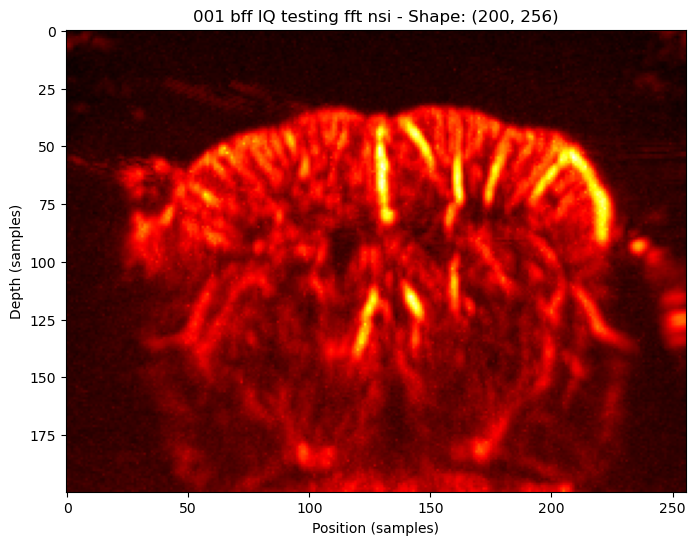

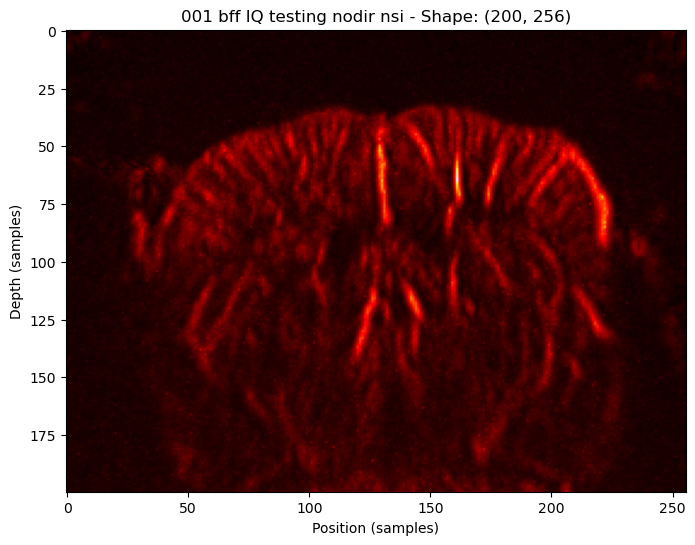

In [7]:
bf_matrices = np.zeros(
        (
        params["image"]["nz"] if params["image"]["nz"] != None else params["image"]["samples_depth"],
        params["image"]["nx"] if params["image"]["nx"] != None else params["image"]["samples_lateral"], 
        len(file_paths)
        )
    )
labels = []

for idx, file_path in enumerate(file_paths):
    
    data = np.load(file_path)

    plt.figure(figsize=(8, 6))
    plt.imshow(np.sqrt(np.abs(data)), aspect='auto', cmap='hot')
    plt.xlabel("Position (samples)")
    plt.ylabel("Depth (samples)")

    bf_matrices[:, :, idx] = data

    label = file_path.strip().split("/")[-1].split(".")[0].replace("_", " ")

    plt.title(f"{label} - Shape: {data.shape}")

    labels.append(label)

    plt.show()

# Comparaison

In [8]:
def calculate_resolution(function):
    half_max = -6 #dB
    left_idx = np.where(function >= half_max)[0][0] #first point where the profile is greater than half max
    right_idx = np.where(function >= half_max)[0][-1] #last point where the profile is greater than half max
    return left_idx, right_idx, right_idx - left_idx

In [9]:
def compare_resolutions(bf_matrices, step_size, lateral_step, labels, profile_x0, profile_y0, lat_len, axial_len, ymin=None, ymax=None, xmin=None, xmax=None):
    
    #viz
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    axes[0].hlines(-6, 0, 0,colors='r', linestyles='--', label='Half max value (-6dB)')
    axes[1].hlines(-6, 0, 0, colors='r', linestyles='--', label='Half max value (-6dB)')


    for i in range(bf_matrices.shape[2]):
        
        lat = bf_matrices[int(profile_x0 - lat_len/2):int(profile_x0 + lat_len/2),profile_y0,i]
        axial = bf_matrices[profile_x0, int(profile_y0 - axial_len): int(profile_y0 + axial_len),i]

        lateral_profile = 20 * np.log10(np.abs(lat) / np.max(np.abs(lat)))
        axial_profile = 20 * np.log10(np.abs(axial) / np.max(np.abs(axial)))

        #calculate resolutions
        lat_left_idx, lat_right_idx, lat_res = calculate_resolution(lateral_profile)
        
        ax_left_idx, ax_right_idx, ax_res = calculate_resolution(axial_profile)
        
        #convert resolutions to meters
        lat_res_m = lat_res * lateral_step
        
        ax_res_m = ax_res * step_size
        
        #plot lateral profiles
        axes[0].plot(lateral_profile, label=f"{labels[i]} - {lat_res_m:.8f} m")
        axes[0].set_title("Lateral Profiles Comparison")
        axes[0].set_xlabel("Lateral position (samples)")
        axes[0].set_ylabel("Power (dB)")
        axes[0].grid(True)
        axes[0].hlines(-6, 0, lateral_profile.shape[0], colors='r', linestyles='--')
        axes[0].set_ylim(ymin, ymax)
        axes[0].set_xlim(xmin, xmax)
        axes[0].legend()
        
        #plot axial profiles
        axes[1].plot(axial_profile, label=f"{labels[i]} - {ax_res_m:.8f} m")
        axes[1].set_title("Axial Profiles Comparison")
        axes[1].set_xlabel("Depth (samples)")
        axes[1].set_ylabel("Power (dB)")
        axes[1].grid(True)
        axes[1].hlines(-6, 0, axial_profile.shape[0], colors='r', linestyles='--')
        axes[1].set_ylim(ymin, ymax)
        axes[1].legend()
        
    plt.tight_layout()
    plt.show()

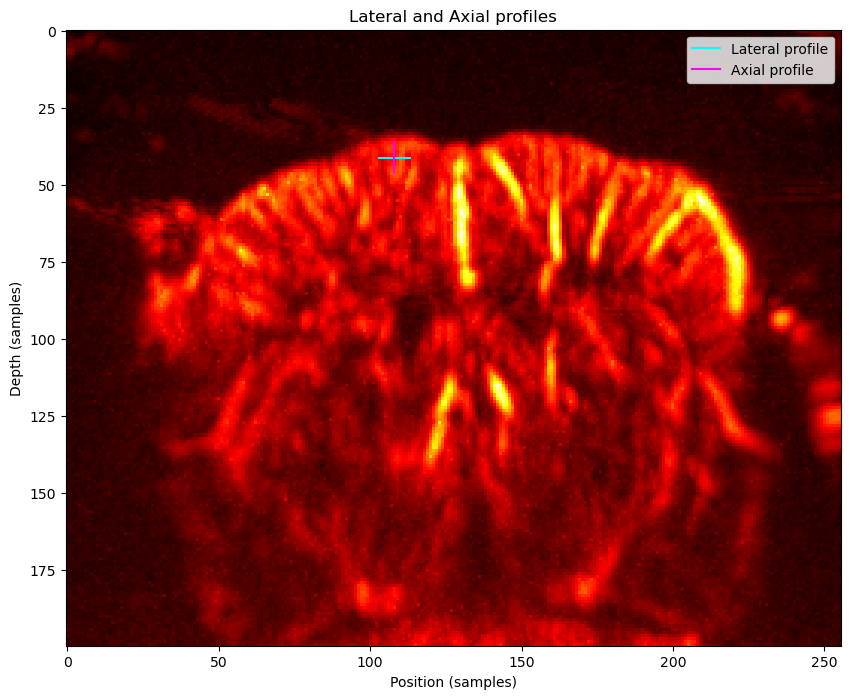

In [18]:
profile_x0 = 108
profile_y0 = 41
lat_len = 10
axial_len = 10

plt.figure(figsize = (10,8))
plt.imshow(np.sqrt(bf_matrices[:,:,0]), cmap='hot', aspect='auto')

plt.plot([profile_x0 - lat_len/2, profile_x0 + lat_len/2], [profile_y0, profile_y0], color='cyan', linestyle='-', label='Lateral profile')
plt.plot([profile_x0, profile_x0], [profile_y0 - axial_len/2, profile_y0 + axial_len/2], color='magenta', linestyle='-', label='Axial profile')

plt.title("Lateral and Axial profiles")
plt.xlabel("Position (samples)")
plt.ylabel("Depth (samples)")
plt.legend()
plt.show()

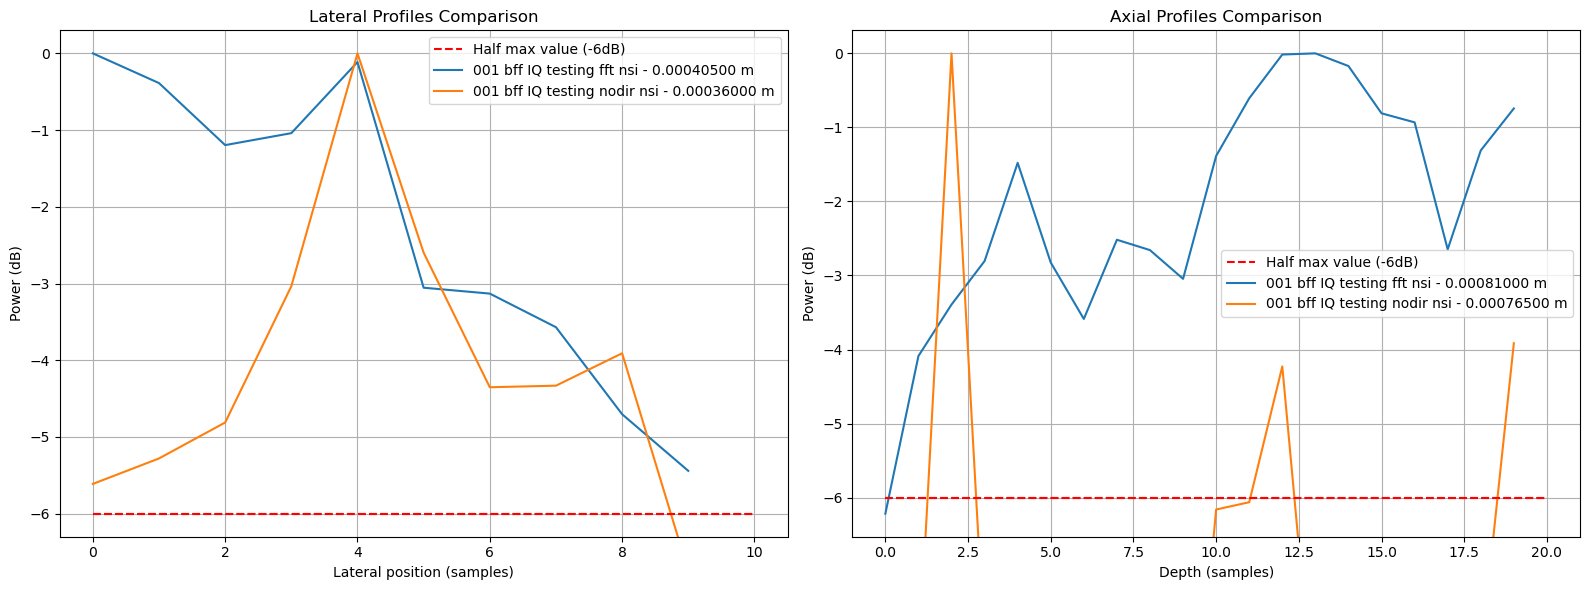

In [19]:
compare_resolutions(bf_matrices, params["image"]["dz"], params["image"]["dx"], labels, profile_x0=profile_x0, profile_y0=profile_y0, lat_len=lat_len, axial_len=axial_len)